# ECE501 — Week 5: Multi-Scale and Adaptive Fabric Defect Detection

This notebook implements the Week 5 objectives on the existing AITEX patch dataset:
- fixed multi-scale and periodicity-adaptive Gabor detection maps;
- multi-radius LBP maps;
- multi-window GLCM texture maps (optional because they are slower);
- mean/max fusion;
- fixed-versus-adaptive comparison and pixel-level metrics.


## 1. Mount Drive and import libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, re, json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from scipy.ndimage import gaussian_filter, uniform_filter
from scipy.signal import find_peaks
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

Mounted at /content/drive
NumPy: 2.1.3
OpenCV: 5.0.0


## 2. Load the existing Week 2 patch dataset

In [2]:
PATCHED_DIR = Path("/content/drive/MyDrive/ECE501/processed_patches")

PATCH_IMAGE_DIR = PATCHED_DIR / "images"
PATCH_MASK_DIR = PATCHED_DIR / "masks"
NODEFECT_PATCH_DIR = PATCHED_DIR / "nodefect_images"

EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def list_images(folder):
    if not folder.exists():
        return []
    return sorted(p for p in folder.rglob("*")
                  if p.is_file() and p.suffix.lower() in EXTENSIONS)

image_paths = list_images(PATCH_IMAGE_DIR)
mask_paths = list_images(PATCH_MASK_DIR)
normal_paths = list_images(NODEFECT_PATCH_DIR)

print("Patch folder:", PATCHED_DIR)
print("Defective-source image patches:", len(image_paths))
print("Mask files:", len(mask_paths))
print("Defect-free patches:", len(normal_paths))

missing = [p for p in [PATCH_IMAGE_DIR, PATCH_MASK_DIR, NODEFECT_PATCH_DIR] if not p.is_dir()]
if missing:
    raise FileNotFoundError("Missing expected folders: " + ", ".join(map(str, missing)))

if not image_paths:
    raise ValueError(f"No image patches found in {PATCH_IMAGE_DIR}")
if not mask_paths:
    raise ValueError(f"No mask patches found in {PATCH_MASK_DIR}")

Patch folder: /content/drive/MyDrive/ECE501/processed_patches
Defective-source image patches: 3222
Mask files: 3222
Defect-free patches: 4371


## 3. Pair images and masks by exact filename

In [3]:
mask_by_name = {p.name.lower(): p for p in mask_paths}
paired_samples = []
pair_rows = []

for ip in image_paths:
    mp = mask_by_name.get(ip.name.lower())
    if mp is None:
        pair_rows.append({"image": ip.name, "mask": None, "status": "missing exact-name mask"})
    else:
        paired_samples.append((ip, mp))
        pair_rows.append({"image": ip.name, "mask": mp.name, "status": "paired"})

pair_report = pd.DataFrame(pair_rows)
print("Exact image-mask pairs:", len(paired_samples), "/", len(image_paths))
display(pair_report["status"].value_counts().rename_axis("status").to_frame("count"))
display(pair_report[pair_report["status"] != "paired"].head(20))

if not paired_samples:
    raise ValueError("No exact-name image-mask pairs found. Check filenames in images/ and masks/.")

Exact image-mask pairs: 3222 / 3222


,count
status,
paired,3222


,image,mask,status


## 4. Inspect valid texture patches and mask encoding

Pairs with nonconstant texture and matching dimensions: 2971
Sample: 0001_002_00_x3328_y0.png
Image min/max/std: 21 182 18.29
Raw mask unique values: [  0 255]
Defect pixels in binary mask: 1395


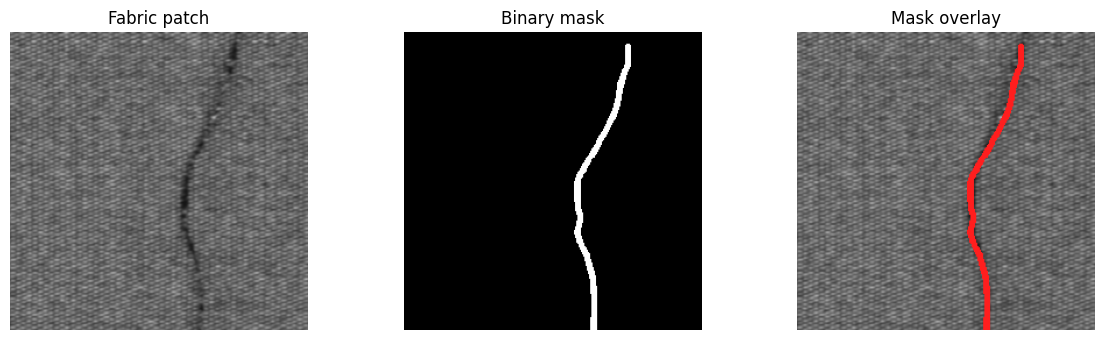

In [4]:
def read_gray(path):
    arr = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if arr is None:
        raise ValueError(f"Could not read {path}")
    return arr

def binary_mask(mask):
    return (np.asarray(mask) > 0).astype(np.uint8)

# Choose a patch with real intensity variation for a meaningful visualization.
valid_texture_pairs = []
for ip, mp in paired_samples:
    im = read_gray(ip)
    ma = read_gray(mp)
    if im.shape == ma.shape and im.std() > 5:
        valid_texture_pairs.append((ip, mp))

print("Pairs with nonconstant texture and matching dimensions:", len(valid_texture_pairs))
if not valid_texture_pairs:
    raise ValueError("No usable texture patches found. Inspect processed_patches/images.")

# Prefer a nonzero-mask patch for visualization if one exists; otherwise show a normal-mask patch.
nonzero_mask_pairs = []
for ip, mp in valid_texture_pairs:
    if np.any(read_gray(mp) > 0):
        nonzero_mask_pairs.append((ip, mp))

sample_pair = nonzero_mask_pairs[0] if nonzero_mask_pairs else valid_texture_pairs[0]
sample_path, sample_mask_path = sample_pair
sample_im = read_gray(sample_path)
sample_mask_raw = read_gray(sample_mask_path)
sample_mask = binary_mask(sample_mask_raw)

print("Sample:", sample_path.name)
print("Image min/max/std:", int(sample_im.min()), int(sample_im.max()), round(float(sample_im.std()), 2))
print("Raw mask unique values:", np.unique(sample_mask_raw)[:20])
print("Defect pixels in binary mask:", int(sample_mask.sum()))
if sample_mask.sum() == 0:
    print("Note: this patch has no marked defect pixels; that can happen when a defect lies in another patch.")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].imshow(sample_im, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Fabric patch")
ax[1].imshow(sample_mask, cmap="gray", vmin=0, vmax=1); ax[1].set_title("Binary mask")
overlay = cv2.cvtColor(sample_im, cv2.COLOR_GRAY2RGB)
overlay[sample_mask > 0] = (255, 30, 30)
ax[2].imshow(overlay); ax[2].set_title("Mask overlay")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Estimate periodicity with autocorrelation and FFT

Periodicity: {'autocorr_period': 5, 'fft_period': 5, 'period': 5, 'confidence': 0.5082682073116302}


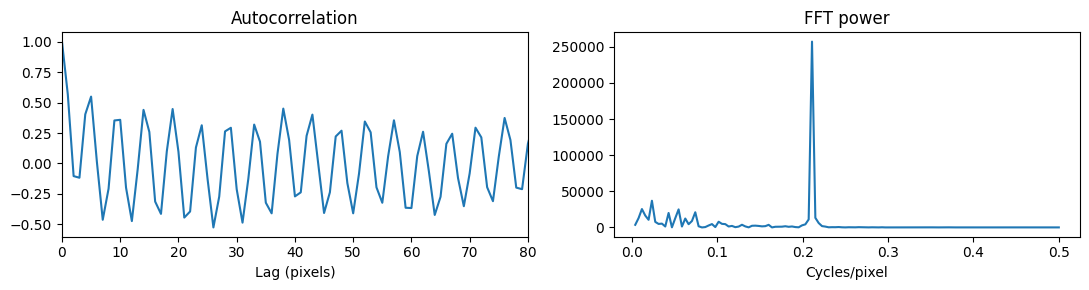

In [5]:
def estimate_periodicity(image, min_period=3, max_period=None, axis=1):
    im = np.asarray(image, dtype=np.float32)
    if im.ndim != 2 or im.std() < 1e-6:
        return {"autocorr_period": None, "fft_period": None, "period": None, "confidence": 0.0}

    # Remove slow illumination variation; then average along rows/columns to get a 1-D profile.
    smooth = gaussian_filter(im, sigma=max(3.0, min(im.shape) / 12))
    highpass = im - smooth
    profile = highpass.mean(axis=0 if axis == 1 else 1)
    profile -= profile.mean()
    if profile.std() < 1e-6:
        return {"autocorr_period": None, "fft_period": None, "period": None, "confidence": 0.0}

    # FFT-based autocorrelation is faster and avoids the full O(n^2) correlation.
    n = len(profile)
    nfft = 1 << (2*n - 1).bit_length()
    spectrum = np.fft.rfft(profile, n=nfft)
    ac = np.fft.irfft(spectrum * np.conjugate(spectrum), n=nfft)[:n]
    ac = ac / max(ac[0], 1e-12)

    max_period = min(max_period or max(min_period + 1, n // 4), n // 2)
    segment = ac[min_period:max_period + 1]
    peaks, _ = find_peaks(segment)
    ac_period, ac_strength = None, 0.0
    if len(peaks):
        peak_lags = peaks + min_period
        best = peak_lags[np.argmax(ac[peak_lags])]
        ac_period, ac_strength = int(best), float(ac[best])

    power = np.abs(np.fft.rfft(profile)) ** 2
    freq = np.fft.rfftfreq(n, d=1.0)
    valid = (freq > 0) & (freq >= 1.0/max_period) & (freq <= 1.0/min_period)
    fft_period, fft_strength = None, 0.0
    if valid.any() and power[valid].max() > 0:
        indices = np.where(valid)[0]
        best_i = indices[np.argmax(power[indices])]
        fft_period = int(round(1.0 / freq[best_i]))
        fft_strength = float(power[best_i] / (power[valid].sum() + 1e-12))

    estimates = [p for p in (ac_period, fft_period) if p is not None]
    period = int(np.median(estimates)) if estimates else None
    confidence = float(np.mean([x for x in (ac_strength, fft_strength) if x > 0])) if estimates else 0.0
    return {"autocorr_period": ac_period, "fft_period": fft_period,
            "period": period, "confidence": confidence}

def plot_periodicity(image):
    im = np.asarray(image, dtype=np.float32)
    highpass = im - gaussian_filter(im, sigma=max(3.0, min(im.shape)/12))
    profile = highpass.mean(axis=0)
    profile -= profile.mean()
    n = len(profile)
    ac = np.correlate(profile, profile, mode="full")[n-1:]
    if ac[0] > 0: ac = ac/ac[0]
    power = np.abs(np.fft.rfft(profile))**2
    freq = np.fft.rfftfreq(n, d=1.0)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].plot(np.arange(len(ac)), ac); ax[0].set_xlim(0, min(80, len(ac)-1))
    ax[0].set_title("Autocorrelation"); ax[0].set_xlabel("Lag (pixels)")
    ax[1].plot(freq[1:], power[1:]); ax[1].set_title("FFT power"); ax[1].set_xlabel("Cycles/pixel")
    plt.tight_layout(); plt.show()

print("Periodicity:", estimate_periodicity(sample_im))
plot_periodicity(sample_im)

## 6. Fixed versus adaptive scales

In [6]:
FIXED_WAVELENGTHS = [4.0, 8.0, 16.0]
ADAPTIVE_MULTIPLIERS = [0.5, 1.0, 2.0]
MIN_WAVELENGTH = 3.0
MAX_WAVELENGTH = 24.0

def adaptive_wavelengths(image):
    info = estimate_periodicity(image)
    period = info["period"]
    if period is None:
        # Fallback is explicit: if periodicity cannot be estimated, use the fixed scales.
        return FIXED_WAVELENGTHS, info, True
    values = sorted(set(
        round(float(np.clip(period * mult, MIN_WAVELENGTH, MAX_WAVELENGTH)), 1)
        for mult in ADAPTIVE_MULTIPLIERS
    ))
    return values, info, False

waves, pinfo, used_fallback = adaptive_wavelengths(sample_im)
print("Fixed wavelengths:", FIXED_WAVELENGTHS)
print("Adaptive wavelengths:", waves)
print("Periodicity info:", pinfo)
print("Used fixed-scale fallback:", used_fallback)

Fixed wavelengths: [4.0, 8.0, 16.0]
Adaptive wavelengths: [3.0, 5.0, 10.0]
Periodicity info: {'autocorr_period': 5, 'fft_period': 5, 'period': 5, 'confidence': 0.5082682073116302}
Used fixed-scale fallback: False


## 7. Multi-scale Gabor maps

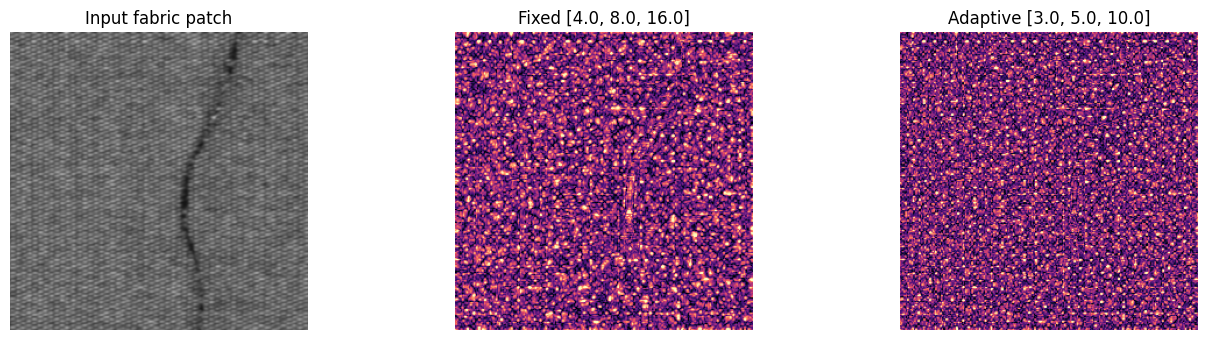

In [7]:
def normalize_map(arr):
    arr = np.asarray(arr, dtype=np.float32)
    if not np.isfinite(arr).all():
        arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    lo, hi = np.percentile(arr, [1, 99])
    if hi - lo < 1e-8:
        return np.zeros_like(arr, dtype=np.float32)
    return np.clip((arr - lo) / (hi - lo), 0, 1)

def gabor_energy(image, wavelength, orientations=4):
    im = image.astype(np.float32) / 255.0
    outputs = []
    for theta in np.linspace(0, np.pi, orientations, endpoint=False):
        ksize = 31
        sigma = max(1.5, wavelength * 0.45)
        kernel = cv2.getGaborKernel((ksize, ksize), sigma, theta,
                                    wavelength, 0.5, 0, ktype=cv2.CV_32F)
        response = cv2.filter2D(im, cv2.CV_32F, kernel)
        outputs.append(np.abs(response))
    return np.mean(outputs, axis=0)

def local_deviation(response, window):
    window = int(max(3, window))
    if window % 2 == 0:
        window += 1
    mean = uniform_filter(response.astype(np.float32), size=window)
    mean_sq = uniform_filter(response.astype(np.float32)**2, size=window)
    std = np.sqrt(np.maximum(mean_sq - mean**2, 1e-8))
    return np.abs(response - mean) / (std + 1e-3)

def gabor_maps(image, wavelengths):
    maps = []
    for wl in wavelengths:
        response = gabor_energy(image, wl)
        dev = local_deviation(response, max(5, int(2*wl + 1)))
        maps.append(normalize_map(dev))
    return maps

def fuse_maps(maps, mode="mean"):
    stack = np.stack([normalize_map(m) for m in maps])
    if mode == "mean":
        result = stack.mean(axis=0)
    elif mode == "max":
        result = stack.max(axis=0)
    else:
        raise ValueError("mode must be 'mean' or 'max'")
    return normalize_map(result)

def fixed_gabor_map(image, fusion="mean"):
    return fuse_maps(gabor_maps(image, FIXED_WAVELENGTHS), fusion)

def adaptive_gabor_map(image, fusion="mean"):
    wavelengths, info, fallback = adaptive_wavelengths(image)
    return fuse_maps(gabor_maps(image, wavelengths), fusion), wavelengths, info, fallback

fixed_score = fixed_gabor_map(sample_im)
adaptive_score, sample_adaptive_waves, sample_period_info, sample_fallback = adaptive_gabor_map(sample_im)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].imshow(sample_im, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Input fabric patch")
ax[1].imshow(fixed_score, cmap="magma", vmin=0, vmax=1); ax[1].set_title(f"Fixed {FIXED_WAVELENGTHS}")
ax[2].imshow(adaptive_score, cmap="magma", vmin=0, vmax=1); ax[2].set_title(f"Adaptive {sample_adaptive_waves}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 8. Multi-radius LBP map

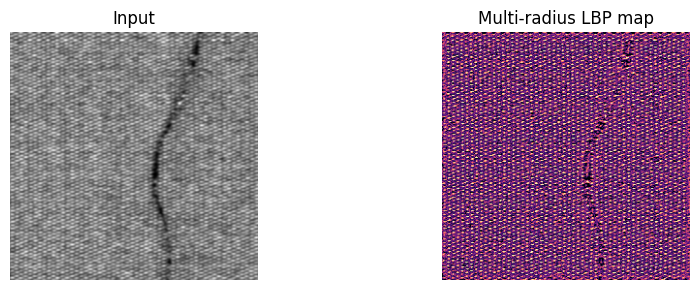

In [8]:
def lbp_multiscale_map(image, radii=(1, 2, 3)):
    image = image.astype(np.uint8)
    maps = []
    for radius in radii:
        points = 8 * radius
        lbp = local_binary_pattern(image, points, radius, method="uniform").astype(np.float32)
        maps.append(normalize_map(local_deviation(lbp, max(5, 2*radius + 5))))
    return fuse_maps(maps, "mean")

lbp_score = lbp_multiscale_map(sample_im)
plt.figure(figsize=(10, 3))
plt.subplot(1, 2, 1); plt.imshow(sample_im, cmap="gray"); plt.title("Input"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(lbp_score, cmap="magma"); plt.title("Multi-radius LBP map"); plt.axis("off")
plt.tight_layout(); plt.show()

## 9. Optional multi-window GLCM map (slower)

In [9]:
def local_glcm_map(image, window=17, levels=16, pixel_step=4):
    # Computes local GLCM only on a grid for speed, then interpolates to full resolution.
    im = (image.astype(np.uint8) // (256 // levels)).clip(0, levels-1)
    h, w = im.shape
    win = int(window)
    if win % 2 == 0: win += 1
    pad = win // 2
    padded = np.pad(im, pad, mode="reflect")
    ys = list(range(0, h, pixel_step))
    xs = list(range(0, w, pixel_step))
    coarse = np.zeros((len(ys), len(xs)), dtype=np.float32)
    for iy, y in enumerate(ys):
        for ix, x in enumerate(xs):
            patch = padded[y:y+win, x:x+win]
            glcm = graycomatrix(patch, distances=[1], angles=[0], levels=levels,
                                symmetric=True, normed=True)
            contrast = graycoprops(glcm, "contrast")[0, 0]
            homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
            coarse[iy, ix] = contrast + (1.0 - homogeneity)
    return normalize_map(cv2.resize(coarse, (w, h), interpolation=cv2.INTER_CUBIC))

RUN_GLCM_PREVIEW = False
if RUN_GLCM_PREVIEW:
    glcm_score = fuse_maps([local_glcm_map(sample_im, w) for w in (9, 17, 33)], "mean")
    plt.figure(figsize=(5, 3)); plt.imshow(glcm_score, cmap="magma"); plt.title("Multi-window GLCM"); plt.axis("off"); plt.show()
else:
    print("GLCM preview skipped for speed. Set RUN_GLCM_PREVIEW=True to run.")

GLCM preview skipped for speed. Set RUN_GLCM_PREVIEW=True to run.


## 10. Threshold maps and evaluate

Sample fixed metrics: {'precision': np.float64(0.026403301414318427), 'recall': np.float64(0.4724014336914176), 'f1': np.float64(0.05001138337093358), 'iou': np.float64(0.025647013037554945), 'gt_defect_pixels': 1395, 'pred_defect_pixels': 24959}
Sample adaptive metrics: {'precision': np.float64(0.02035208243881407), 'recall': np.float64(0.33978494623631555), 'f1': np.float64(0.03840388889477787), 'iou': np.float64(0.01957787782412872), 'gt_defect_pixels': 1395, 'pred_defect_pixels': 23290}


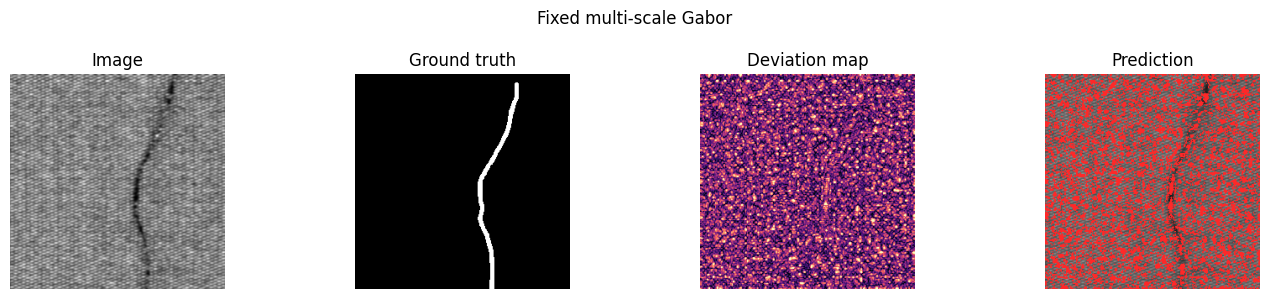

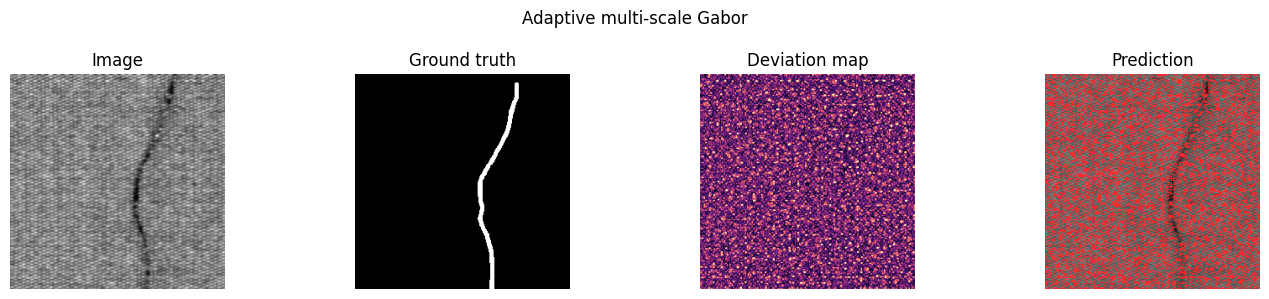

In [10]:
def otsu_prediction(score):
    score8 = np.uint8(np.clip(normalize_map(score) * 255, 0, 255))
    if score8.max() == score8.min():
        return np.zeros_like(score8, dtype=np.uint8)
    _, pred = cv2.threshold(score8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return pred.astype(np.uint8)

def pixel_metrics(gt, pred):
    gt = binary_mask(gt).astype(bool).ravel()
    pred = binary_mask(pred).astype(bool).ravel()
    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2*precision*recall / (precision+recall+1e-9)
    iou = tp / (tp+fp+fn+1e-9)
    return {"precision": precision, "recall": recall, "f1": f1, "iou": iou,
            "gt_defect_pixels": int(gt.sum()), "pred_defect_pixels": int(pred.sum())}

def get_gt_mask(image_path, mask_path):
    image = read_gray(image_path)
    mask = read_gray(mask_path)
    if image.shape != mask.shape:
        raise ValueError(f"Shape mismatch: {image_path.name}: {image.shape}, {mask_path.name}: {mask.shape}")
    return image, binary_mask(mask)

gt = sample_mask
fixed_pred = otsu_prediction(fixed_score)
adaptive_pred = otsu_prediction(adaptive_score)
print("Sample fixed metrics:", pixel_metrics(gt, fixed_pred))
print("Sample adaptive metrics:", pixel_metrics(gt, adaptive_pred))

def show_result(image, gt, score, pred, title):
    overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    overlay[pred > 0] = (255, 40, 40)
    fig, ax = plt.subplots(1, 4, figsize=(14, 3))
    ax[0].imshow(image, cmap="gray"); ax[0].set_title("Image")
    ax[1].imshow(gt, cmap="gray"); ax[1].set_title("Ground truth")
    ax[2].imshow(score, cmap="magma"); ax[2].set_title("Deviation map")
    ax[3].imshow(overlay); ax[3].set_title("Prediction")
    for a in ax: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_result(sample_im, sample_mask, fixed_score, fixed_pred, "Fixed multi-scale Gabor")
show_result(sample_im, sample_mask, adaptive_score, adaptive_pred, "Adaptive multi-scale Gabor")

## 11. Run a small, validated fixed-versus-adaptive evaluation

Evaluated patches: 30
Skipped patches: 0


,image,gt_defect_pixels,period_px,autocorr_period_px,fft_period_px,adaptive_wavelengths,used_fixed_fallback,fixed_precision,fixed_recall,fixed_f1,fixed_iou,fixed_gt_defect_pixels,fixed_pred_defect_pixels,adaptive_precision,adaptive_recall,adaptive_f1,adaptive_iou,adaptive_gt_defect_pixels,adaptive_pred_defect_pixels
0,0001_002_00_x1024_y0.png,0,49,47.0,51,[24.0],False,0.0,0.0,0.0,0.0,0,30652,0.0,0.0,0.0,0.0,0,20243
1,0001_002_00_x1152_y0.png,0,9,14.0,5,"[4.5, 9.0, 18.0]",False,0.0,0.0,0.0,0.0,0,24661,0.0,0.0,0.0,0.0,0,26034
2,0001_002_00_x1280_y0.png,0,9,14.0,5,"[4.5, 9.0, 18.0]",False,0.0,0.0,0.0,0.0,0,25073,0.0,0.0,0.0,0.0,0,26459
3,0001_002_00_x1408_y0.png,0,12,19.0,5,"[6.0, 12.0, 24.0]",False,0.0,0.0,0.0,0.0,0,24802,0.0,0.0,0.0,0.0,0,27443
4,0001_002_00_x1536_y0.png,0,5,5.0,5,"[3.0, 5.0, 10.0]",False,0.0,0.0,0.0,0.0,0,25049,0.0,0.0,0.0,0.0,0,24042
5,0001_002_00_x1664_y0.png,0,5,5.0,5,"[3.0, 5.0, 10.0]",False,0.0,0.0,0.0,0.0,0,25120,0.0,0.0,0.0,0.0,0,23705
6,0001_002_00_x1792_y0.png,0,12,19.0,5,"[6.0, 12.0, 24.0]",False,0.0,0.0,0.0,0.0,0,24337,0.0,0.0,0.0,0.0,0,27009
7,0001_002_00_x1920_y0.png,0,5,5.0,5,"[3.0, 5.0, 10.0]",False,0.0,0.0,0.0,0.0,0,24157,0.0,0.0,0.0,0.0,0,23012
8,0001_002_00_x2048_y0.png,0,5,5.0,5,"[3.0, 5.0, 10.0]",False,0.0,0.0,0.0,0.0,0,25167,0.0,0.0,0.0,0.0,0,22980
9,0001_002_00_x2176_y0.png,0,12,19.0,5,"[6.0, 12.0, 24.0]",False,0.0,0.0,0.0,0.0,0,25267,0.0,0.0,0.0,0.0,0,26819


,Fixed mean,Adaptive mean
precision,0.001764,0.001355
recall,0.031493,0.022676
f1,0.003340,0.002557
iou,0.001713,0.001304


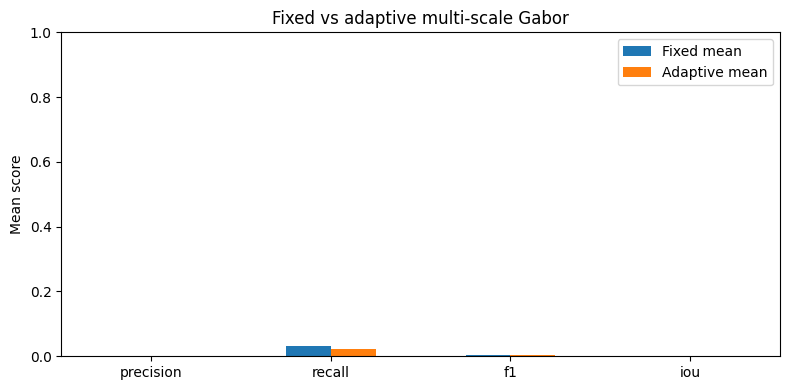

In [11]:
# Start with 30 paired patches. Increase after checking visual outputs.
MAX_EVAL = 30
eval_rows = []
skipped_rows = []

for ip, mp in valid_texture_pairs[:MAX_EVAL]:
    try:
        im, gt = get_gt_mask(ip, mp)
        fixed = fixed_gabor_map(im)
        adaptive, waves, pinfo, fallback = adaptive_gabor_map(im)
        fixed_pred = otsu_prediction(fixed)
        adaptive_pred = otsu_prediction(adaptive)
        fm = pixel_metrics(gt, fixed_pred)
        am = pixel_metrics(gt, adaptive_pred)
        row = {
            "image": ip.name,
            "gt_defect_pixels": int(gt.sum()),
            "period_px": pinfo["period"],
            "autocorr_period_px": pinfo["autocorr_period"],
            "fft_period_px": pinfo["fft_period"],
            "adaptive_wavelengths": str(waves),
            "used_fixed_fallback": fallback,
        }
        row.update({f"fixed_{k}": v for k, v in fm.items()})
        row.update({f"adaptive_{k}": v for k, v in am.items()})
        eval_rows.append(row)
    except Exception as exc:
        skipped_rows.append({"image": ip.name, "reason": str(exc)})

results_df = pd.DataFrame(eval_rows)
skipped_df = pd.DataFrame(skipped_rows)
print("Evaluated patches:", len(results_df))
print("Skipped patches:", len(skipped_df))
if len(results_df):
    display(results_df.head(10))
    metric_names = ["precision", "recall", "f1", "iou"]
    summary = pd.DataFrame({
        "Fixed mean": [results_df[f"fixed_{m}"].mean() for m in metric_names],
        "Adaptive mean": [results_df[f"adaptive_{m}"].mean() for m in metric_names],
    }, index=metric_names)
    display(summary)
    summary.plot(kind="bar", ylim=(0, 1), figsize=(8, 4), rot=0)
    plt.title("Fixed vs adaptive multi-scale Gabor")
    plt.ylabel("Mean score")
    plt.tight_layout(); plt.show()
else:
    print("No evaluation completed. Check valid_texture_pairs and mask files.")
if len(skipped_df):
    display(skipped_df.head(10))